# Random Walk Task (Sutton & Barto, Examples 6.2 and 6.3)

A Markov Reward Process with 5 non-terminal states `A, B, C, D, E` laid out in a line, bounded by two terminal states on the left and right:

```
[term] <-0- A <-0- B <-0- C <-0- D <-0- E -1-> [term]
```

- Every episode starts in `C`.
- From any non-terminal state, the agent moves left or right with equal probability (0.5 / 0.5).
- All transitions give reward 0, except the transition into the right terminal state, which gives reward +1.
- Undiscounted ($\gamma = 1$), episodic.

This notebook estimates $v_\pi$ from sampled experience using TD(0), and compares it against the analytically-derived true values.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [13]:
def adjustAxeProperties(ax_obj, x_fontsize, x_rotation, y_fontsize, y_rotation):
    for tick in ax_obj.xaxis.get_major_ticks():
        tick.label1.set_fontsize(x_fontsize)
        tick.label1.set_rotation(x_rotation)
    for tick in ax_obj.yaxis.get_major_ticks():
        tick.label1.set_fontsize(y_fontsize)
        tick.label1.set_rotation(y_rotation)

## Environment setup

States are encoded as integers `0..6`:
- `0` = left terminal state
- `6` = right terminal state
- `1, 2, 3, 4, 5` = `A, B, C, D, E`

Episodes always start at state `3` (`C`).

In [5]:
START_STATE = 3
LEFT_TERMINAL = 0
RIGHT_TERMINAL = 6
TERMINAL_STATES = (LEFT_TERMINAL, RIGHT_TERMINAL)
NON_TERMINAL_STATES = [1, 2, 3, 4, 5]
STATE_LABELS = ["A", "B", "C", "D", "E"]

# --------------------------------------------------------------------------
# Deriving the true values v_pi(s) analytically
#
# Under the random policy, the Bellman equation for state s is:
#     v(s) = 0.5 * [r(s, left)  + gamma * v(left)]
#          + 0.5 * [r(s, right) + gamma * v(right)]
#
# With gamma = 1, v(terminal) = 0 (no reward can ever be earned after
# entering a terminal state), and reward = 0 everywhere except on the
# transition E -> right terminal (reward = 1), this expands to 5 linear
# equations in 5 unknowns:
#
#     v(A) = 0.5*v(0) + 0.5*v(B)         = 0.5*v(B)
#     v(B) = 0.5*v(A) + 0.5*v(C)
#     v(C) = 0.5*v(B) + 0.5*v(D)
#     v(D) = 0.5*v(C) + 0.5*v(E)
#     v(E) = 0.5*v(D) + 0.5*(1 + v(6))   = 0.5*v(D) + 0.5
#
# Solving this system gives v(A..E) = 1/6, 2/6, 3/6, 4/6, 5/6.
#
# Intuition (gambler's ruin): since the only nonzero reward is the +1
# earned on absorption at the right terminal, v(s) is exactly the
# probability of a symmetric random walk started at s being absorbed on
# the right before the left. For a line of n non-terminal positions, that
# probability from position i (1-indexed) is i / (n + 1). Here n = 5, so
# v(i) = i / 6 -- matching the equations above.
# --------------------------------------------------------------------------
TRUE_VALUES = np.array([0, 1 / 6, 2 / 6, 3 / 6, 4 / 6, 5 / 6, 0])

## Episode generation

Plays out one episode under the equiprobable random policy, starting from `START_STATE`, until a terminal state is reached. Returns the full list of visited states (including the terminal one it ends on) and the list of rewards received on each transition.

In [3]:
def generate_episode(start_state=START_STATE):
    state = start_state
    states = [state]
    rewards = []
    while state not in (LEFT_TERMINAL, RIGHT_TERMINAL):
        step = -1 if np.random.rand() < 0.5 else 1
        next_state = state + step
        reward = 1.0 if next_state == RIGHT_TERMINAL else 0.0
        states.append(next_state)
        rewards.append(reward)
        state = next_state
    return states, rewards

In [4]:
# Quick sanity check
np.random.seed(0)
states, rewards = generate_episode()
states, rewards

([3, 4, 5, 6], [0.0, 0.0, 1.0])

## TD(0) policy evaluation

After every transition $S_t \to S_{t+1}$ with reward $R_{t+1}$, update:

$$V(S_t) \leftarrow V(S_t) + \alpha \big[ R_{t+1} + \gamma V(S_{t+1}) - V(S_t) \big]$$

with $\gamma = 1$ and $V(\text{terminal}) = 0$. Unlike Monte Carlo, this update happens after each individual step, using the current (possibly still-wrong) estimate of $V(S_{t+1})$ as a bootstrap target — the episode doesn't need to finish before `V(S_t)` is updated.

In [8]:
def td0_evaluate_episode(values, alpha=0.1, gamma=1.0):
    """Run one episode, updating `values` in place with TD(0), one step at a time."""
    states, rewards = generate_episode()
    for t in range(len(rewards)):
        s, s_next = states[t], states[t + 1]
        v_next = 0.0 if s_next in TERMINAL_STATES else values[s_next]
        values[s] += alpha * (rewards[t] + gamma * v_next - values[s])
    return states, rewards

In [9]:
# Quick sanity check
np.random.seed(1)
values = np.zeros(7)
values[NON_TERMINAL_STATES] = 0.5
initial_values = values.copy()

for _ in range(100):
    td0_evaluate_episode(values, alpha=0.1)

print("initial:    ", initial_values[NON_TERMINAL_STATES])
print("after 100 episodes:", values[NON_TERMINAL_STATES])
print("true values:", TRUE_VALUES[NON_TERMINAL_STATES])

# Terminal state values must never move
assert values[LEFT_TERMINAL] == 0.0 and values[RIGHT_TERMINAL] == 0.0

# Estimates should have moved closer to the true values on average
initial_error = np.sqrt(np.mean((initial_values[NON_TERMINAL_STATES] - TRUE_VALUES[NON_TERMINAL_STATES]) ** 2))
final_error = np.sqrt(np.mean((values[NON_TERMINAL_STATES] - TRUE_VALUES[NON_TERMINAL_STATES]) ** 2))
assert final_error < initial_error
print(f"RMS error: initial={initial_error:.4f}, final={final_error:.4f}")

initial:     [0.5 0.5 0.5 0.5 0.5]
after 100 episodes: [0.07796672 0.33075977 0.55260048 0.73360178 0.82261326]
true values: [0.16666667 0.33333333 0.5        0.66666667 0.83333333]
RMS error: initial=0.2357, final=0.0552


## Estimated values as training progresses

Reproduces the left panel of Example 6.2: TD(0) with $\alpha = 0.1$, starting from $V_0(s) = 0.5$ for all non-terminal states, snapshotted after 0, 1, 10, and 100 episodes and compared against the true values.

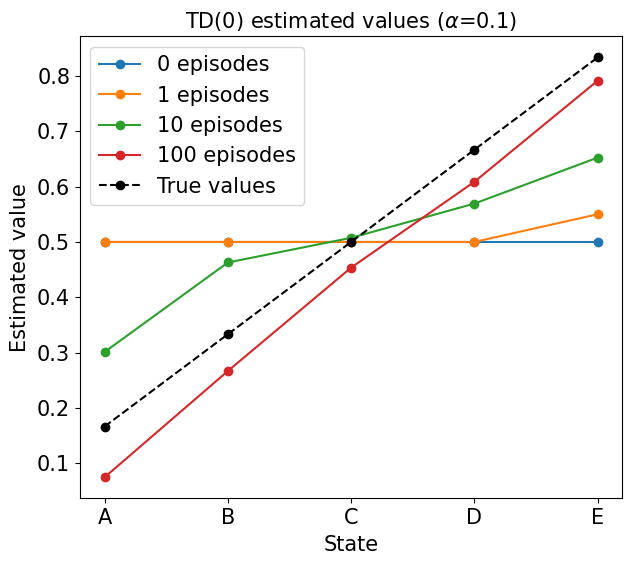

In [17]:
def plot_estimated_values(alpha=0.1, snapshots=(0, 1, 10, 100), seed=0):
    fontsize = 15
    np.random.seed(seed)
    values = np.zeros(7)
    values[NON_TERMINAL_STATES] = 0.5

    fig, ax = plt.subplots(figsize=(7, 6))
    max_episodes = max(snapshots)
    for episode in range(max_episodes + 1):
        if episode in snapshots:
            ax.plot(STATE_LABELS, values[NON_TERMINAL_STATES], marker="o", label=f"{episode} episodes")
        if episode < max_episodes:
            td0_evaluate_episode(values, alpha=alpha)

    ax.plot(STATE_LABELS, TRUE_VALUES[NON_TERMINAL_STATES], marker="o", linestyle="--",
            color="black", label="True values")
    adjustAxeProperties(ax, fontsize, 0, fontsize, 0)
    ax.set_xlabel("State", fontsize=fontsize, labelpad=5)
    ax.set_ylabel("Estimated value", fontsize=fontsize, labelpad=5)
    ax.set_title(f"TD(0) estimated values ($\\alpha$={alpha})", fontsize=fontsize)
    ax.legend(loc="best", fontsize=fontsize)
    plt.show()

plot_estimated_values()

## RMS-error learning curves

Reproduces the TD side of the right panel of Figure 6.6: for several step sizes $\alpha$, run TD(0) for 100 episodes, measure the RMS error between current estimates and $v_\pi$ averaged over the 5 states, and average that error curve over many independent runs to smooth out noise.

In [11]:
def rms_error(values):
    diffs = values[NON_TERMINAL_STATES] - TRUE_VALUES[NON_TERMINAL_STATES]
    return np.sqrt(np.mean(diffs ** 2))


def td0_learning_curve(alpha, num_episodes=100, num_runs=100):
    """Average RMS error vs. episode number for TD(0) with a fixed alpha,
    averaged over `num_runs` independent runs."""
    errors = np.zeros(num_episodes + 1)
    for _ in range(num_runs):
        values = np.zeros(7)
        values[NON_TERMINAL_STATES] = 0.5
        for episode in range(num_episodes + 1):
            errors[episode] += rms_error(values)
            td0_evaluate_episode(values, alpha=alpha)
    errors /= num_runs
    return errors

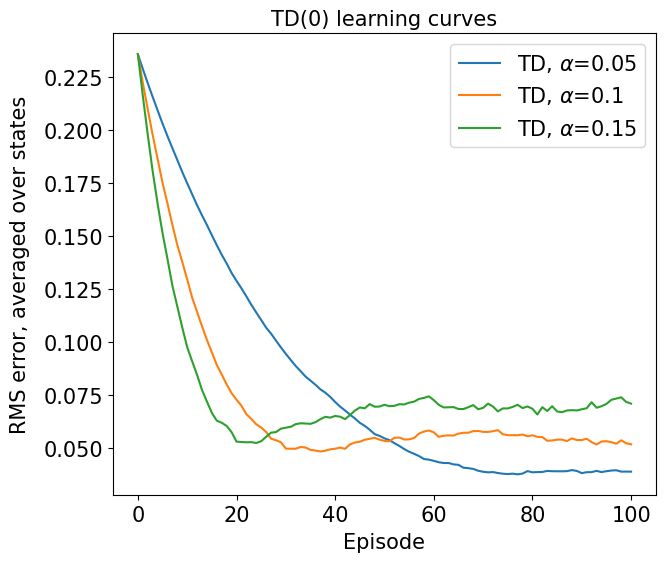

In [16]:
fontsize = 15
td_alphas = [0.05, 0.1, 0.15]

fig, ax = plt.subplots(figsize=(7, 6))
for alpha in td_alphas:
    errors = td0_learning_curve(alpha)
    ax.plot(errors, label=f"TD, $\\alpha$={alpha}")

adjustAxeProperties(ax, fontsize, 0, fontsize, 0)
ax.set_xlabel("Episode", fontsize=fontsize, labelpad=5)
ax.set_ylabel("RMS error, averaged over states", fontsize=fontsize, labelpad=10)
ax.set_title("TD(0) learning curves", fontsize=fontsize)
ax.legend(loc="best", fontsize=fontsize)
plt.show()

## Batch updating

So far, `td0_evaluate_episode` applies an update immediately after each step and then discards the episode. Under **batch updating**, we instead fix a set of `k` episodes (the "training set") and repeatedly sweep over all of them, accumulating what each transition's TD(0) update *would be* under the current `V` — without applying any of it mid-sweep. Only after a full sweep do we apply the summed increment (scaled by a small $\alpha$). We repeat these sweeps until `V` stops changing (converges), and only then measure the error.

This requires **storing** each episode's `(states, rewards)` rather than discarding it, since the same episodes are replayed on every sweep. `generate_episode()` already returns exactly what we need to store — no changes needed there.

In [18]:
# Storing a batch of episodes for replay.
#
# Each entry is the (states, rewards) tuple that generate_episode() already
# produces -- we just keep it around instead of throwing it away.
np.random.seed(0)
batch = [generate_episode() for _ in range(10)]

len(batch), batch[0]

(10, ([3, 4, 5, 6], [0.0, 0.0, 1.0]))

### One batch sweep

`td0_batch_increment` walks every transition of every stored episode exactly once, accumulating the TD(0) increment each transition would produce under the current `values` — without modifying `values` along the way. The caller is responsible for applying the returned increment and deciding whether to sweep again.

In [19]:
def td0_batch_increment(values, episodes, gamma=1.0):
    """Sweep once over a fixed batch of stored (states, rewards) episodes and
    return the total TD(0) increment per state, computed entirely under the
    current `values` (which this function does not modify)."""
    increment = np.zeros_like(values)
    for states, rewards in episodes:
        for t in range(len(rewards)):
            s, s_next = states[t], states[t + 1]
            v_next = 0.0 if s_next in TERMINAL_STATES else values[s_next]
            increment[s] += rewards[t] + gamma * v_next - values[s]
    return increment

In [20]:
# Quick sanity check
values = np.zeros(7)
values[NON_TERMINAL_STATES] = 0.5
before = values.copy()

increment = td0_batch_increment(values, batch)

# values must be left untouched by this call -- it only computes, never applies
assert np.array_equal(values, before)

# terminal states never receive an increment
assert increment[LEFT_TERMINAL] == 0.0 and increment[RIGHT_TERMINAL] == 0.0

print("increment:", increment)

increment: [ 0.  -2.5  0.   0.   0.   2.5  0. ]


### Sweeping to convergence

`batch_converge` repeatedly calls `td0_batch_increment` on the same fixed batch and applies `alpha * increment` after each sweep, stopping once the increment is negligible (`max(|increment|) < tol`) — i.e. `V` has stabilized for this particular batch. `alpha` is deliberately small here, since a full batch's worth of increments gets summed before being applied once; the large `alpha=0.1` used for online TD(0) would overshoot badly.

In [29]:
def batch_converge(episodes, alpha=0.001, tol=1e-3, max_sweeps=50_000):
    """Starting from V(s)=0.5 for non-terminal states, repeatedly sweep over
    the fixed `episodes` batch with td0_batch_increment, applying alpha times
    the increment after each sweep, until the increment is negligible (below
    `tol`) or `max_sweeps` is reached. Returns the converged `values`.

    Note: with alpha this small, convergence genuinely takes thousands of
    sweeps (each sweep is cheap, so this is still fast in practice) -- a
    too-low max_sweeps will silently return a not-yet-converged result. The
    smallest batches (k=1-2 episodes) are the slowest to converge in sweep
    count (observed up to ~28,000 sweeps for a single episode), which is
    why the default here has headroom well beyond that.
    """
    values = np.zeros(7)
    values[NON_TERMINAL_STATES] = 0.5

    converged = False
    for _ in range(max_sweeps):
        increment = td0_batch_increment(values, episodes)
        values += alpha * increment
        if np.max(np.abs(increment)) < tol:
            converged = True
            break

    if not converged:
        print(f"Warning: batch_converge did not converge within {max_sweeps} sweeps "
              f"(final max|increment|={np.max(np.abs(increment)):.5f})")

    return values

In [30]:
# Quick sanity check
converged_values = batch_converge(batch)

print("converged:  ", converged_values[NON_TERMINAL_STATES])
print("true values:", TRUE_VALUES[NON_TERMINAL_STATES])

# Terminal state values must never move
assert converged_values[LEFT_TERMINAL] == 0.0 and converged_values[RIGHT_TERMINAL] == 0.0

# At convergence, the next sweep's increment should be essentially zero
assert np.max(np.abs(td0_batch_increment(converged_values, batch))) < 1e-3
print("converged: increment at the fixed point is ~0, as expected")

converged:   [0.10245624 0.27306258 0.50039735 0.63926886 0.77806725]
true values: [0.16666667 0.33333333 0.5        0.66666667 0.83333333]
converged: increment at the fixed point is ~0, as expected


### Growing the training set

For each independent run, grow the batch one episode at a time from 1 up to `max_episodes`. At every size `k`, call `batch_converge` on the batch-so-far (from scratch each time) and record the RMS error of the converged estimate. Averaging this error-vs-`k` curve over many independent runs gives the "batch training" learning curve: how good is the TD(0) fixed-point estimate as a function of how much experience it was given, with learning always fully exhausted at each point.

Note on cost: `batch_converge` turns out to need *fewer* sweeps as the batch grows (bigger batches produce bigger raw increments at the same `alpha`, so the random-walk-style relaxation covers the same ground in fewer sweeps) — so despite the nested loop this stays fast; one full run (`max_episodes=100`) takes a couple of seconds. `num_runs=30` below is a reasonable default (roughly a minute total); bump it up for a smoother curve.

In [31]:
def batch_training_curve(max_episodes=100, num_runs=30, alpha=0.001, tol=1e-3, seed=0):
    """For each of num_runs independent runs, grow a batch from 1 to
    max_episodes episodes one at a time; at each size, converge TD(0) on
    the batch-so-far and record the RMS error. Returns the error curve
    averaged over all runs (length max_episodes, indexed by batch size - 1)."""
    np.random.seed(seed)
    errors = np.zeros(max_episodes)
    for run in range(num_runs):
        episodes = []
        for k in range(max_episodes):
            episodes.append(generate_episode())
            converged_values = batch_converge(episodes, alpha=alpha, tol=tol)
            errors[k] += rms_error(converged_values)
        if (run + 1) % 5 == 0 or run == num_runs - 1:
            print(f"  run {run + 1}/{num_runs} done")
    errors /= num_runs
    return errors

  run 5/30 done
  run 10/30 done
  run 15/30 done
  run 20/30 done
  run 25/30 done
  run 30/30 done


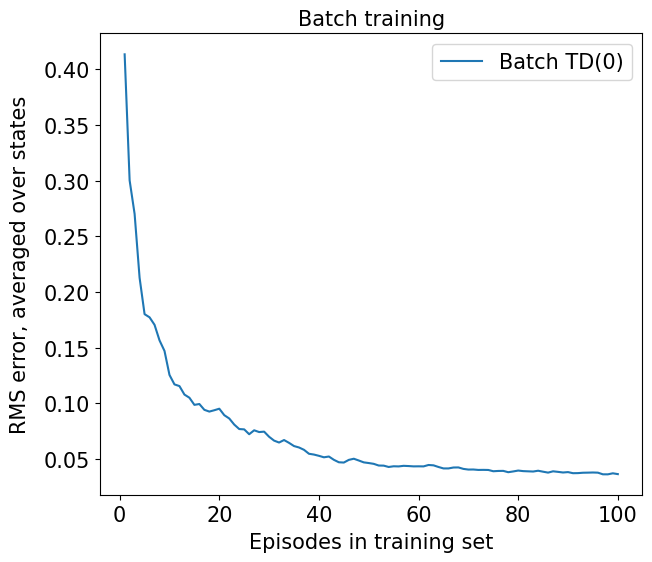

In [32]:
batch_errors = batch_training_curve(max_episodes=100, num_runs=30)

fontsize = 15
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(range(1, 101), batch_errors, label="Batch TD(0)")

adjustAxeProperties(ax, fontsize, 0, fontsize, 0)
ax.set_xlabel("Episodes in training set", fontsize=fontsize, labelpad=5)
ax.set_ylabel("RMS error, averaged over states", fontsize=fontsize, labelpad=10)
ax.set_title("Batch training", fontsize=fontsize)
ax.legend(loc="best", fontsize=fontsize)
plt.show()